# Phase 5 — Modélisation et comparaison

**Objectif :** trouver le modèle qui classe le mieux les clients par risque de départ, **et** qui fournit des probabilités fiables, en comparant équitablement plusieurs familles de modèles.

**Plan**
1. Comparaison des modèles par défaut
2. Traitement du déséquilibre des classes
3. Optimisation des hyperparamètres (Optuna)
4. Choix du modèle final et sauvegarde

**Protocole commun** : même pipeline (Phase 4), mêmes plis de validation croisée (5 plis × 3 répétitions), **jeu d'entraînement uniquement**. Le jeu de test reste sous clé jusqu'à la Phase 6.

| Métrique | Rôle |
|---|---|
| **PR-AUC** | Métrique principale : qualité du classement des clients à risque (adaptée au déséquilibre) |
| ROC-AUC | Comparaison avec la littérature |
| **Brier** | Fiabilité des probabilités (plus bas = mieux). Essentiel : le gain attendu de la Phase 6 se calcule à partir de ces probabilités |

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from churn.config import RANDOM_STATE
from churn.data import load_clean
from churn.features import split_data, build_pipeline
from churn.models import evaluate_cv, make_cv, results_table, corrected_paired_ttest
from churn.viz import set_style, save_fig, fmt_pct, BLUE, ORANGE, TEXT, TEXT_SECONDARY, GRID

warnings.filterwarnings("ignore", category=UserWarning)
set_style()
X_train, X_test, y_train, y_test = split_data(load_clean())
cv = make_cv()
del X_test, y_test  # sous clé jusqu'à la Phase 6
print(f"Entraînement : {len(X_train)} clients, {fmt_pct(y_train.mean())} de churn")

Entraînement : 5634 clients, 26,5 % de churn


## 1. Comparaison des modèles par défaut

In [2]:
default_models = {
    "Dummy (taux moyen)": DummyClassifier(strategy="prior"),
    "Régression logistique": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
    "XGBoost": XGBClassifier(random_state=RANDOM_STATE, n_jobs=1),
    "LightGBM": LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, n_jobs=1),
}
results_default = {name: evaluate_cv(build_pipeline(m), X_train, y_train, cv=cv)
                   for name, m in default_models.items()}
table_default = results_table(results_default)
table_default.style.format({"pr_auc": "{:.4f}", "pr_auc_std": "{:.4f}", "roc_auc": "{:.4f}",
                            "brier": "{:.4f}", "fit_time": "{:.2f} s"})

,pr_auc,pr_auc_std,roc_auc,brier,fit_time
Régression logistique,0.6747,0.0171,0.8512,0.1327,0.13 s
LightGBM,0.6480,0.0212,0.8360,0.1399,0.22 s
Random Forest,0.6198,0.0300,0.8224,0.1459,1.97 s
XGBoost,0.6180,0.0233,0.8203,0.1513,0.51 s
Dummy (taux moyen),0.2654,0.0001,0.5000,0.1949,0.16 s


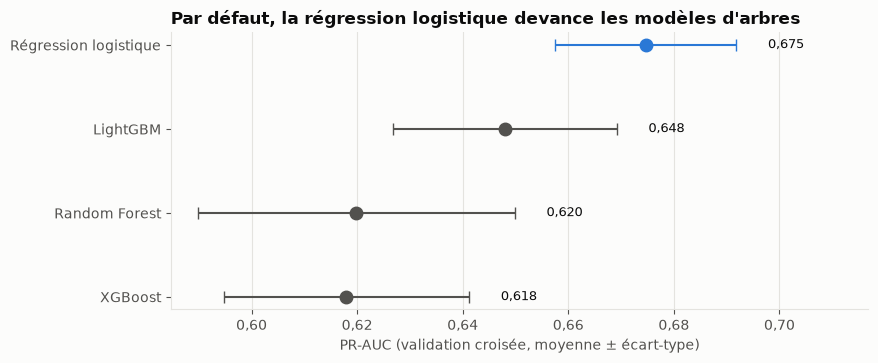

In [3]:
def plot_scores(table, title, filename, highlight=None):
    """Graphique en points : PR-AUC moyenne ± écart-type (axe tronqué → pas de barres)."""
    t = table.iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(t) + 1.4))
    for i, (name, row) in enumerate(t.iterrows()):
        color = BLUE if name == highlight else TEXT_SECONDARY
        ax.errorbar(row["pr_auc"], i, xerr=row["pr_auc_std"], fmt="o", markersize=9,
                    color=color, ecolor=color, elinewidth=1.5, capsize=4)
        ax.text(row["pr_auc"] + row["pr_auc_std"] + 0.006, i, f"{row['pr_auc']:.3f}".replace(".", ","),
                va="center", fontsize=9, color=TEXT)
    ax.set_xlim(right=(t["pr_auc"] + t["pr_auc_std"]).max() + 0.025)
    ax.set_yticks(range(len(t)), t.index)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.2f}".replace(".", ","))
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("PR-AUC (validation croisée, moyenne ± écart-type)")
    ax.set_title(title)
    save_fig(fig, filename)
    plt.show()

plot_scores(table_default.drop(index="Dummy (taux moyen)"),
            "Par défaut, la régression logistique devance les modèles d'arbres",
            "05_modeles_defaut.png", highlight="Régression logistique")

**Lecture :**
- Le **Dummy** obtient une PR-AUC de 0,265 (= le taux de churn) : c'est le plancher. Tous les modèles le dépassent très largement.
- La **régression logistique** arrive en tête (0,675), avec les **meilleures probabilités** (Brier le plus bas).
- Les modèles d'arbres par défaut sont **moins bons et plus instables** (écarts-types plus élevés). Pourquoi ? Vérifions s'ils sur-apprennent.

In [4]:
rows = []
for name in ["Régression logistique", "Random Forest", "XGBoost", "LightGBM"]:
    pipe = build_pipeline(default_models[name]).fit(X_train, y_train)
    train_score = average_precision_score(y_train, pipe.predict_proba(X_train)[:, 1])
    rows.append({"modèle": name, "PR-AUC entraînement": train_score,
                 "PR-AUC validation croisée": results_default[name]["pr_auc"]})
overfit = pd.DataFrame(rows).set_index("modèle")
overfit["écart"] = overfit["PR-AUC entraînement"] - overfit["PR-AUC validation croisée"]
overfit.style.format("{:.3f}")

,PR-AUC entraînement,PR-AUC validation croisée,écart
modèle,,,
Régression logistique,0.679,0.675,0.004
Random Forest,1.000,0.620,0.380
XGBoost,0.935,0.618,0.317
LightGBM,0.841,0.648,0.193


**Diagnostic : sur-apprentissage.** Le Random Forest atteint une PR-AUC quasi parfaite (~1,0) sur les clients qu'il a vus à l'entraînement, mais bien moins sur des clients nouveaux. Il a **appris par cœur** (arbres profonds jusqu'à des feuilles d'un seul client). XGBoost et LightGBM sur-apprennent aussi, à un degré moindre. La régression logistique a un écart très faible : elle **généralise**.

C'est attendu avec les réglages par défaut, pensés pour de gros datasets. Sur 5 600 clients, il faut **contraindre** les arbres (profondeur, taille minimale des feuilles, taux d'apprentissage) : c'est l'objet de la section 3.

## 2. Traitement du déséquilibre des classes

Avec 26,5 % de churners, le réflexe habituel est de « rééquilibrer » :
- **`class_weight="balanced"`** : les erreurs sur les churners pèsent ~2,8 fois plus lourd dans l'apprentissage.
- **SMOTE** : création de churners **synthétiques** par interpolation, jusqu'à 50/50. Il est appliqué **à l'intérieur** de chaque pli (pipeline `imbalanced-learn`), sinon des clients synthétiques dérivés des clients de validation fuiraient dans l'entraînement.

On teste les deux sur la régression logistique et sur un LightGBM **contraint** (arbres peu profonds, apprentissage lent : réglages raisonnables avant l'optimisation de la section 3).

In [5]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

def with_smote(model):
    """Insère SMOTE entre le prétraitement et le modèle (appliqué uniquement aux plis d'entraînement)."""
    base = build_pipeline(model)
    return ImbPipeline(base.steps[:-1] + [("smote", SMOTE(random_state=RANDOM_STATE)), ("model", model)])

lgbm_params = dict(n_estimators=300, learning_rate=0.03, num_leaves=8, random_state=RANDOM_STATE, verbose=-1, n_jobs=1)
strategies = {
    ("Régression logistique", "Aucune"): build_pipeline(LogisticRegression(max_iter=2000)),
    ("Régression logistique", "class_weight"): build_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced")),
    ("Régression logistique", "SMOTE"): with_smote(LogisticRegression(max_iter=2000)),
    ("LightGBM contraint", "Aucune"): build_pipeline(LGBMClassifier(**lgbm_params)),
    ("LightGBM contraint", "class_weight"): build_pipeline(LGBMClassifier(**lgbm_params, class_weight="balanced")),
    ("LightGBM contraint", "SMOTE"): with_smote(LGBMClassifier(**lgbm_params)),
}
imbalance = pd.DataFrame([
    {"modèle": m, "stratégie": s, **{k: v for k, v in evaluate_cv(est, X_train, y_train, cv=cv).items()
                                     if not k.endswith("_folds")}}
    for (m, s), est in strategies.items()
]).set_index(["modèle", "stratégie"])
imbalance[["pr_auc", "pr_auc_std", "roc_auc", "brier"]].style.format("{:.4f}")

**Résultat contre-intuitif :**
- **PR-AUC et ROC-AUC ne s'améliorent jamais** : au mieux inchangées (−0,001 à −0,002, dans le bruit), au pire en baisse (SMOTE sur LightGBM : −0,010). Rééquilibrer ne rend pas le modèle meilleur pour **classer** les clients.
- En revanche, le **score de Brier se dégrade** dans tous les cas (de 0,133 à 0,142–0,161) : les probabilités deviennent **fausses**.

Pourquoi ? Rééquilibrer revient à faire croire au modèle que 50 % des clients partent. Il **surestime donc systématiquement** le risque. La courbe de calibration le montre :

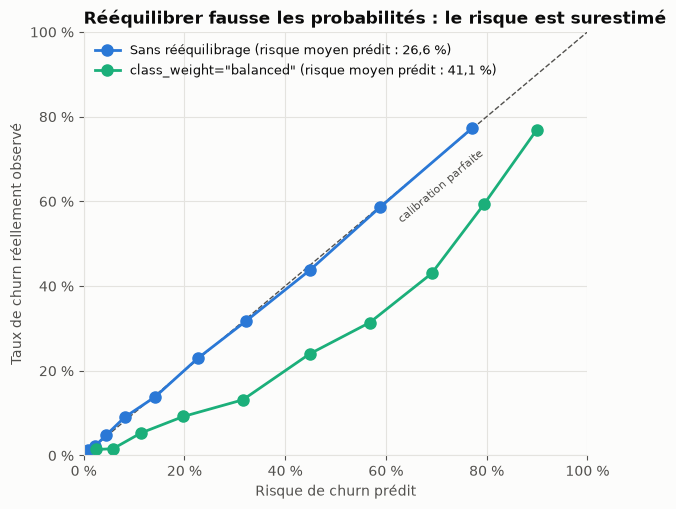

Taux de churn réel : 26,5 %


In [6]:
from sklearn.calibration import calibration_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from churn.viz import AQUA

cv_simple = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
calib = {}
for label, key, color in [("Sans rééquilibrage", ("Régression logistique", "Aucune"), BLUE),
                          ("class_weight=\"balanced\"", ("Régression logistique", "class_weight"), AQUA)]:
    proba = cross_val_predict(strategies[key], X_train, y_train, cv=cv_simple, method="predict_proba")[:, 1]
    frac_pos, mean_pred = calibration_curve(y_train, proba, n_bins=10, strategy="quantile")
    calib[label] = (mean_pred, frac_pos, color, proba.mean())

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot([0, 1], [0, 1], ls="--", lw=1, color=TEXT_SECONDARY)
ax.text(0.62, 0.55, "calibration parfaite", rotation=40, fontsize=8, color=TEXT_SECONDARY)
for label, (x, y, color, mean_p) in calib.items():
    ax.plot(x, y, marker="o", markersize=8, lw=2, color=color,
            label=f"{label} (risque moyen prédit : {fmt_pct(mean_p)})")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Risque de churn prédit", ylabel="Taux de churn réellement observé")
ax.xaxis.set_major_formatter(lambda v, _: fmt_pct(v, 0))
ax.yaxis.set_major_formatter(lambda v, _: fmt_pct(v, 0))
ax.legend(loc="upper left", fontsize=9)
ax.set_title("Rééquilibrer fausse les probabilités : le risque est surestimé")
save_fig(fig, "05_calibration_reequilibrage.png")
plt.show()
print(f"Taux de churn réel : {fmt_pct(y_train.mean())}")

**Lecture :** sans rééquilibrage, la courbe suit la diagonale : quand le modèle annonce 40 % de risque, environ 40 % de ces clients partent réellement. Avec `class_weight`, la courbe passe **nettement sous la diagonale** : le modèle annonce par exemple ~57 % de risque pour des clients qui ne partent qu'à ~31 %. Son risque moyen prédit (41 %) est **1,5 fois** le taux réel (26,5 %).

**Décision : aucun rééquilibrage.**
- Le rééquilibrage ne fait que **déplacer le seuil de décision** implicite, sans améliorer le classement.
- Or notre cas d'usage a besoin de **probabilités fiables** : le gain attendu d'une action (Phase 6) vaut `probabilité × valeur du client × taux de succès − coût`. Avec des probabilités surestimées, on surestimerait le gain de la campagne.
- Le déséquilibre sera traité **au bon endroit** : par le **choix du seuil de décision** optimisant le gain net (Phase 6).

## 3. Optimisation des hyperparamètres (Optuna)

**Optuna** explore l'espace des hyperparamètres par **optimisation bayésienne** (TPE) : chaque essai tient compte des précédents pour se concentrer sur les zones prometteuses. C'est bien plus efficace qu'une grille exhaustive.

**Précautions :**
- **Plis de recherche ≠ plis d'évaluation.** Optuna optimise la PR-AUC sur une validation croisée à 5 plis (graine 2024). La meilleure configuration est ensuite **réévaluée** sur le protocole commun (5 × 3, graine 42). Sinon, le score retenu serait optimiste : on aurait « sur-appris » les plis de validation.
- **Espaces de recherche** orientés par le diagnostic de sur-apprentissage : régularisation, arbres peu profonds, apprentissage lent.

| Modèle | Hyperparamètres explorés |
|---|---|
| Régression logistique | `C` (inverse de la force de régularisation), `l1_ratio` (0 = L2, 1 = L1, entre = Elastic Net) |
| LightGBM | nombre d'arbres, taux d'apprentissage, nombre de feuilles, taille minimale des feuilles, sous-échantillonnage des lignes et des colonnes, régularisation L2 |
| XGBoost | idem, avec la profondeur maximale et le poids minimal des feuilles |

In [7]:
import optuna
from sklearn.model_selection import StratifiedKFold, cross_val_score

optuna.logging.set_verbosity(optuna.logging.WARNING)
search_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)  # ≠ plis d'évaluation

def make_lr(trial):
    return LogisticRegression(C=trial.suggest_float("C", 1e-3, 10, log=True),
                              l1_ratio=trial.suggest_float("l1_ratio", 0.0, 1.0),
                              solver="saga", max_iter=5000)

def make_lgbm(trial):
    return LGBMClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 800, step=50),
        learning_rate=trial.suggest_float("learning_rate", 0.005, 0.2, log=True),
        num_leaves=trial.suggest_int("num_leaves", 4, 48),
        min_child_samples=trial.suggest_int("min_child_samples", 10, 150),
        subsample=trial.suggest_float("subsample", 0.5, 1.0), subsample_freq=1,
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 30, log=True),
        random_state=RANDOM_STATE, verbose=-1, n_jobs=1)

def make_xgb(trial):
    return XGBClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 800, step=50),
        learning_rate=trial.suggest_float("learning_rate", 0.005, 0.2, log=True),
        max_depth=trial.suggest_int("max_depth", 2, 6),
        min_child_weight=trial.suggest_float("min_child_weight", 1, 30, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 30, log=True),
        random_state=RANDOM_STATE, n_jobs=1)

def tune(model_factory, n_trials):
    def objective(trial):
        pipe = build_pipeline(model_factory(trial))
        return cross_val_score(pipe, X_train, y_train, cv=search_cv, scoring="average_precision", n_jobs=-1).mean()
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=n_trials)
    return study

studies = {
    "Régression logistique": tune(make_lr, 40),
    "LightGBM": tune(make_lgbm, 60),
    "XGBoost": tune(make_xgb, 60),
}
for name, study in studies.items():
    print(f"{name:22s} meilleure PR-AUC (plis de recherche) : {study.best_value:.4f} après {len(study.trials)} essais")

Régression logistique  meilleure PR-AUC (plis de recherche) : 0.6740 après 40 essais
LightGBM               meilleure PR-AUC (plis de recherche) : 0.6704 après 60 essais
XGBoost                meilleure PR-AUC (plis de recherche) : 0.6726 après 60 essais


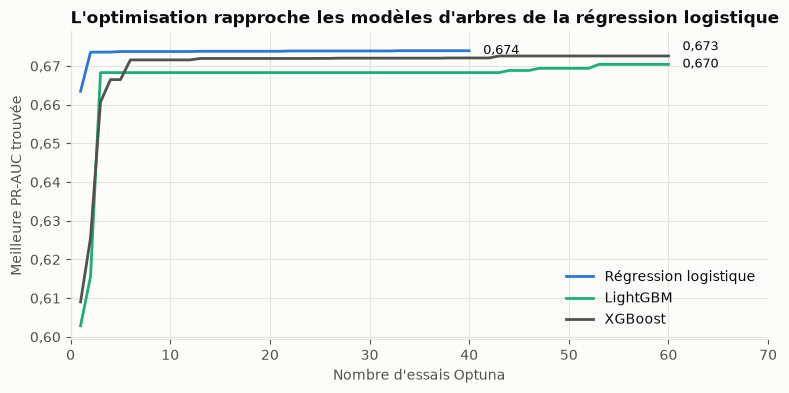

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
colors = {"Régression logistique": BLUE, "LightGBM": AQUA, "XGBoost": TEXT_SECONDARY}
label_pos = []
for name, study in studies.items():
    values = [t.value for t in study.trials]
    best_so_far = np.maximum.accumulate(values)
    ax.plot(range(1, len(values) + 1), best_so_far, lw=2, color=colors[name], label=name)
    label_pos.append([best_so_far[-1], best_so_far[-1], len(values)])
# Écarte verticalement les étiquettes de fin trop proches, si elles sont à la même abscisse
label_pos.sort(key=lambda t: (t[2], t[0]))
for i in range(1, len(label_pos)):
    if label_pos[i][2] == label_pos[i - 1][2]:
        label_pos[i][1] = max(label_pos[i][1], label_pos[i - 1][1] + 0.0045)
ax.set_ylim(top=max(t[1] for t in label_pos) + 0.004)
for value, y_text, x_end in label_pos:
    ax.text(x_end + 1, y_text, f" {value:.3f}".replace(".", ","), va="center", fontsize=9, color=TEXT)
ax.set_xlim(0, 70)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.2f}".replace(".", ","))
ax.set_xlabel("Nombre d'essais Optuna")
ax.set_ylabel("Meilleure PR-AUC trouvée")
ax.legend(loc="lower right")
ax.set_title("L'optimisation rapproche les modèles d'arbres de la régression logistique")
save_fig(fig, "05_optuna_historique.png")
plt.show()

### 3.1 Réévaluation des meilleures configurations sur le protocole commun

In [9]:
best_params = {name: study.best_params for name, study in studies.items()}
tuned_models = {
    "Régression logistique (optimisée)": LogisticRegression(**best_params["Régression logistique"], solver="saga", max_iter=5000),
    "LightGBM (optimisé)": LGBMClassifier(**best_params["LightGBM"], subsample_freq=1, random_state=RANDOM_STATE, verbose=-1, n_jobs=1),
    "XGBoost (optimisé)": XGBClassifier(**best_params["XGBoost"], random_state=RANDOM_STATE, n_jobs=1),
}
results_tuned = {name: evaluate_cv(build_pipeline(m), X_train, y_train, cv=cv) for name, m in tuned_models.items()}
results_all = {"Régression logistique (défaut)": results_default["Régression logistique"],
               "LightGBM (défaut)": results_default["LightGBM"],
               "XGBoost (défaut)": results_default["XGBoost"], **results_tuned}
table_all = results_table(results_all)
table_all.style.format({"pr_auc": "{:.4f}", "pr_auc_std": "{:.4f}", "roc_auc": "{:.4f}",
                        "brier": "{:.4f}", "fit_time": "{:.2f} s"})

,pr_auc,pr_auc_std,roc_auc,brier,fit_time
Régression logistique (défaut),0.6747,0.0171,0.8512,0.1327,0.13 s
Régression logistique (optimisée),0.6746,0.0173,0.8511,0.1326,0.16 s
XGBoost (optimisé),0.6720,0.0187,0.8504,0.1331,3.03 s
LightGBM (optimisé),0.6695,0.0190,0.8496,0.1336,0.40 s
LightGBM (défaut),0.6480,0.0212,0.8360,0.1399,0.22 s
XGBoost (défaut),0.6180,0.0233,0.8203,0.1513,0.51 s


In [10]:
for name, params in best_params.items():
    print(name, {k: round(v, 4) if isinstance(v, float) else v for k, v in params.items()})

Régression logistique {'C': 0.1127, 'l1_ratio': 0.2107}
LightGBM {'n_estimators': 350, 'learning_rate': 0.0108, 'num_leaves': 11, 'min_child_samples': 78, 'subsample': 0.9299, 'colsample_bytree': 0.5186, 'reg_lambda': 1.3136}
XGBoost {'n_estimators': 800, 'learning_rate': 0.0133, 'max_depth': 2, 'min_child_weight': 13.5734, 'subsample': 0.6871, 'colsample_bytree': 0.4071, 'reg_lambda': 0.1029}


## 4. Choix du modèle final

### 4.1 Les écarts sont-ils significatifs ?

On compare chaque modèle optimisé au meilleur, **pli par pli** (mêmes 15 plis), avec le **t-test corrigé de Nadeau & Bengio**. Les plis de validation croisée se chevauchent, et un t-test classique conclurait trop facilement à une différence.

In [11]:
ranking = results_table(results_tuned)
best_name = ranking.index[0]
comparisons = []
for name in ranking.index[1:]:
    test = corrected_paired_ttest(results_tuned[best_name]["pr_auc_folds"], results_tuned[name]["pr_auc_folds"])
    comparisons.append({"comparaison": f"{best_name} vs {name}", **test})
pd.DataFrame(comparisons).set_index("comparaison").style.format(
    {"mean_diff": "{:+.4f}", "t_stat": "{:.2f}", "p_value": "{:.3f}", "win_rate": "{:.0%}"})

,mean_diff,t_stat,p_value,win_rate
comparaison,,,,
Régression logistique (optimisée) vs XGBoost (optimisé),+0.0027,0.72,0.482,60%
Régression logistique (optimisée) vs LightGBM (optimisé),+0.0051,1.06,0.306,67%


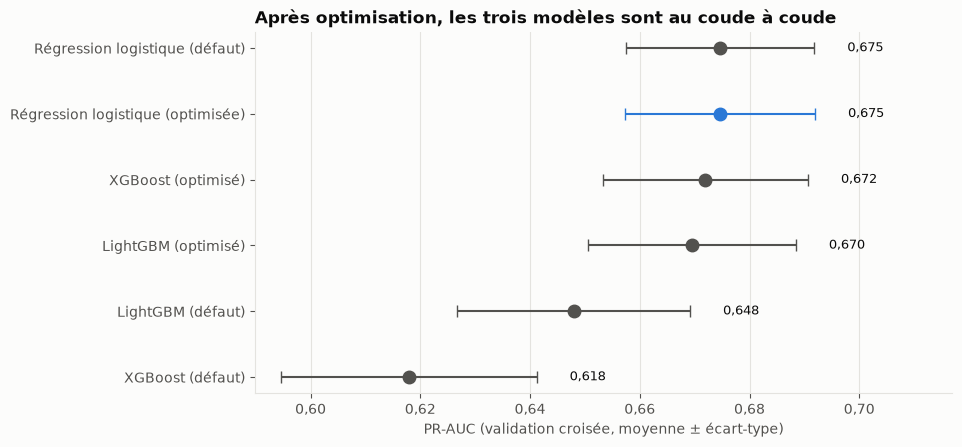

In [12]:
plot_scores(table_all, "Après optimisation, les trois modèles sont au coude à coude",
            "05_modeles_optimises.png", highlight='Régression logistique (optimisée)')

**Lecture :** après optimisation, les trois modèles sont **statistiquement indiscernables** : les écarts de PR-AUC (quelques millièmes) sont très inférieurs à la variabilité entre plis (±0,02), et le t-test corrigé ne détecte aucune différence significative (p > 0,05). L'optimisation a beaucoup aidé les arbres (XGBoost : +0,054) mais rien apporté à la régression logistique, déjà bien réglée par défaut.

Indice révélateur : le meilleur XGBoost utilise des arbres de **profondeur 2**, c'est-à-dire des interactions très simples. La structure du problème est **quasi additive**, ce qui explique qu'un modèle linéaire suffise.

### Décision : régression logistique optimisée

À performance égale, on départage sur les autres critères :

| Critère | Régression logistique | XGBoost / LightGBM |
|---|---|---|
| Performance (PR-AUC) | 0,675 | 0,670–0,672 (écart non significatif) |
| Calibration (Brier) | **0,1326** (la meilleure) | 0,1331–0,1336 |
| Interprétabilité | **Native** : chaque coefficient se lit comme un effet sur le risque | Nécessite des outils post-hoc |
| Simplicité | Entraînement en ~0,2 s, fichier léger, aucune dépendance supplémentaire | 2 à 20 fois plus lent, dépendances lourdes |

La version optimisée (`C ≈ 0,11`, `l1_ratio ≈ 0,21`) est préférée à la version par défaut à performance identique : sa **régularisation plus forte** (Elastic Net) la rend plus robuste et peut annuler les coefficients inutiles.

*Limite :* pour XGBoost, le nombre d'arbres retenu (800) est à la borne de l'espace de recherche ; l'élargir pourrait grappiller un peu, sans changer la conclusion vu l'ampleur du bruit.

> **À retenir :** le modèle le plus complexe n'est pas toujours le meilleur. Ici, la régression logistique est aussi performante, mieux calibrée, plus rapide et explicable, ce qui est un atout majeur face à des équipes métier.

### 4.2 Entraînement final et sauvegarde

Le modèle retenu est réentraîné sur **tout le jeu d'entraînement** (5 634 clients), puis sauvegardé avec sa fiche de métadonnées.

In [13]:
from churn.config import SELECTED_FEATURES, DROPPED_COLS
from churn.models import save_model

chosen_name = 'Régression logistique (optimisée)'
final_pipeline = build_pipeline(tuned_models[chosen_name]).fit(X_train, y_train)
r = results_tuned[chosen_name]
path = save_model(final_pipeline, "churn_model", {
    "model": chosen_name,
    "estimator": type(final_pipeline.named_steps["model"]).__name__,
    "hyperparameters": final_pipeline.named_steps["model"].get_params(),
    "features_added": SELECTED_FEATURES,
    "features_dropped": DROPPED_COLS,
    "n_train": int(len(X_train)),
    "train_churn_rate": float(y_train.mean()),
    "cv_protocol": "RepeatedStratifiedKFold 5x3 (random_state=42), jeu d'entraînement",
    "cv_pr_auc": round(r["pr_auc"], 4), "cv_pr_auc_std": round(r["pr_auc_std"], 4),
    "cv_roc_auc": round(r["roc_auc"], 4), "cv_brier": round(r["brier"], 4),
})
print("Modèle sauvegardé :", path.name, f"({path.stat().st_size / 1024:.0f} Ko)")

Modèle sauvegardé : churn_model.joblib (10 Ko)


In [14]:
from churn.models import load_model

reloaded, card = load_model("churn_model")
sample = X_train.head(5)
assert np.allclose(reloaded.predict_proba(sample), final_pipeline.predict_proba(sample))
print("Relecture OK — probabilités identiques. Fiche :")
{k: v for k, v in card.items() if k != "hyperparameters"}

Relecture OK — probabilités identiques. Fiche :


{'name': 'churn_model',
 'created_at': '2026-11-19T15:54:14+00:00',
 'sklearn_version': '1.9.1',
 'pandas_version': '3.1.1',
 'model': 'Régression logistique (optimisée)',
 'estimator': 'LogisticRegression',
 'features_added': ['log_tenure', 'fiber_month_to_month'],
 'features_dropped': ['gender', 'PhoneService', 'TotalCharges'],
 'n_train': 5634,
 'train_churn_rate': 0.2653532126375577,
 'cv_protocol': "RepeatedStratifiedKFold 5x3 (random_state=42), jeu d'entraînement",
 'cv_pr_auc': 0.6746,
 'cv_pr_auc_std': 0.0173,
 'cv_roc_auc': 0.8511,
 'cv_brier': 0.1326}

## Conclusion de la Phase 5

- **5 familles de modèles** comparées équitablement (même pipeline, mêmes 15 plis).
- Les modèles d'arbres par défaut **sur-apprennent** ; une fois contraints et optimisés, ils rejoignent la régression logistique sans la dépasser significativement.
- **Rééquilibrer les classes n'améliore pas le classement et fausse les probabilités** : le déséquilibre sera traité par le seuil de décision (Phase 6).
- Le modèle final est choisi sur **quatre critères** (performance testée statistiquement, calibration, interprétabilité, simplicité), et non sur le seul score.
- Prochaine étape : **évaluation sur le jeu de test** (enfin !) et **optimisation business du seuil**.